# Извлечение именованных сущностей (NER). Часть 1: анализ и подготовка данных

**Автор:** Куницын Денис

**Дата:** 19 августа

## Цель и задачи

**Бизнес-задача:** сервису медиамониторинга «Эхолот» нужно автоматически находить в текстах упоминания персон, организаций и локаций.

**Цель в терминах Machine Learning:** дообучить `bert-base-multilingual-cased` для задачи распознавания именованных сущностей (token classification) и оценить, как качество зависит от объёма размеченных данных.

Проект состоит из двух тетрадок. В этой части данные исследуются и готовятся для BERT; обучение моделей, эксперименты и анализ ошибок — во второй части (`Извлечение именованных сущностей. Часть 2 — эксперименты.ipynb`).

**Задачи этой части:**

1. Изучить разметку WikiANN и примеры размеченных предложений.
2. Проанализировать распределение типов сущностей и длин предложений.
3. Токенизировать предложения и выровнять NER-метки с подтокенами BERT.
4. Проверить корректность выравнивания и динамического паддинга.

## Данные

**Датасет:** [WikiANN](https://huggingface.co/datasets/unimelb-nlp/wikiann), русскоязычная конфигурация. Типы сущностей: `PER`, `ORG`, `LOC`. Схема разметки — IOB2.

**Токенизатор:** `bert-base-multilingual-cased`.

## Структура тетрадки

- Шаг 1 — подготовка окружения и обеспечение воспроизводимости.
- Шаг 2 — знакомство с данными и EDA.
- Шаг 3 — токенизация и выравнивание меток.

## Шаг 1. Подготовка окружения и обеспечение воспроизводимости

Установка зависимостей, импорт библиотек и фиксация `SEED`.

In [1]:
# Установка библиотек
%pip install -q numpy pandas matplotlib torch transformers datasets seqeval spacy


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: .venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
from collections import Counter
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from datasets import load_dataset
from seqeval.metrics.sequence_labeling import get_entities
from spacy import displacy
from transformers import (
    AutoTokenizer,
    DataCollatorForTokenClassification,
    set_seed,
)


.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
SEED = 42
set_seed(SEED)

print("Версии: " + ", ".join(
    f"{package}={version(package)}"
    for package in [
        "torch",
        "transformers",
        "datasets",
        "seqeval",
        "spacy",
    ]
))

Версии: torch=2.13.0, transformers=5.15.1, datasets=5.0.1, seqeval=1.2.2, spacy=3.8.15


## Шаг 2. Знакомство с данными и их анализ

WikiANN построен автоматически на основе статей Википедии. Один пример содержит
исходные `tokens`, числовые `ner_tags` и служебные поля `langs`, `spans`.

В IOB2 каждая новая сущность начинается с `B-*`, её продолжение размечается `I-*`,
а токены вне сущностей — `O`. При подсчёте распределения одна метка `B-*`
соответствует одной сущности.


In [4]:
# Загрузка русскоязычной конфигурации WikiANN
raw_datasets = load_dataset("unimelb-nlp/wikiann", "ru")

print(f"Размер обучающей выборки:   {len(raw_datasets['train'])}")
print(f"Размер валидационной:       {len(raw_datasets['validation'])}")
print(f"Размер тестовой:            {len(raw_datasets['test'])}")

# Получаем метки из структуры датасета
label_list = raw_datasets["train"].features["ner_tags"].feature.names
id2label = {i: label for i, label in enumerate(label_list)}
label2id = {label: i for i, label in enumerate(label_list)}
ENTITY_TYPES = sorted({
    label.split("-")[-1]
    for label in label_list
    if label != "O"
})

print(f"Метки: {label_list}")
print(f"Типы сущностей: {ENTITY_TYPES}")


Размер обучающей выборки:   20000
Размер валидационной:       10000
Размер тестовой:            10000
Метки: ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
Типы сущностей: ['LOC', 'ORG', 'PER']


### Анализ примеров разметки

Первые два примера из обучающей выборки: исходный текст и пары «токен — строковая метка» для размеченных сущностей.

In [5]:
# Дополняем вывод двух примеров
for i in range(2):
    tokens = raw_datasets["train"][i]["tokens"]
    tags = [label_list[tag] for tag in raw_datasets["train"][i]["ner_tags"]]

    # Выводим предложение и токены с метками, отличными от O
    print(f"Пример {i + 1}: {' '.join(tokens)}")
    for token, tag in zip(tokens, tags):
        if tag != "O":
            print(f"    {token:<20} -> {tag}")
    print()


Пример 1: Илизаров , Гавриил Абрамович
    Илизаров             -> B-PER
    ,                    -> I-PER
    Гавриил              -> I-PER
    Абрамович            -> I-PER

Пример 2: ' '' Рыбницкий район '' '
    Рыбницкий            -> B-LOC
    район                -> I-LOC



### Демонстрация сущностей

Три предложения из валидационной выборки с подсвеченными сущностями; многословные сущности отображаются единым фрагментом.

In [6]:
def visualize_ner(example, label_list):
    """Подсвечивает целые IOB2-сущности в одном примере WikiANN."""
    tokens = example["tokens"]
    tags = [label_list[tag] for tag in example["ner_tags"]]
    text = " ".join(tokens)

    offsets = []
    cursor = 0
    for token in tokens:
        offsets.append((cursor, cursor + len(token)))
        cursor += len(token) + 1

    ents = [
        {
            "start": offsets[start][0],
            "end": offsets[end][1],
            "label": entity_type,
        }
        for entity_type, start, end in get_entities(tags)
    ]
    displacy.render(
        {"text": text, "ents": ents},
        style="ent",
        manual=True,
        jupyter=True,
    )


# Вызываем visualize_ner для трёх примеров из валидационной выборки
for i in range(3):
    print(f"Пример {i + 1} из валидационной выборки:")
    visualize_ner(raw_datasets["validation"][i], label_list)


Пример 1 из валидационной выборки:


Пример 2 из валидационной выборки:


Пример 3 из валидационной выборки:


### Анализ распределения сущностей

Количество сущностей `PER`, `ORG`, `LOC` в обучающей выборке считается по меткам `B-*` — метки `I-*` отдельными сущностями не считаются.

Распределение сущностей в обучающей выборке (по меткам B-*):
  LOC :  9498 (38.56%)
  ORG :  7944 (32.25%)
  PER :  7187 (29.18%)
  Всего сущностей: 24629


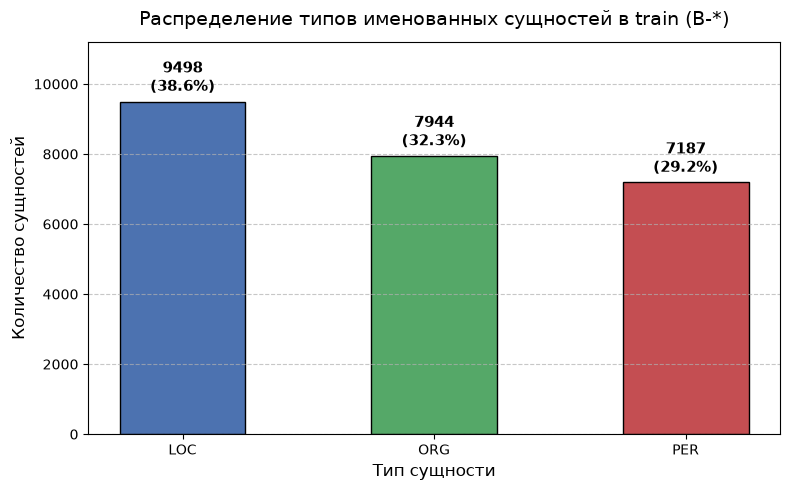

In [7]:
# Формируем список типов сущностей по тегам B-*
entity_types = []
for tags in raw_datasets["train"]["ner_tags"]:
    for tag in tags:
        str_tag = label_list[tag]
        if str_tag.startswith("B-"):
            entity_types.append(str_tag.split("-")[-1])

type_counts = Counter(entity_types)
total_entities = sum(type_counts.values())

print("Распределение сущностей в обучающей выборке (по меткам B-*):")
for entity_type in ENTITY_TYPES:
    count = type_counts[entity_type]
    pct = (count / total_entities) * 100
    print(f"  {entity_type:4s}: {count:5d} ({pct:5.2f}%)")
print(f"  Всего сущностей: {total_entities}")

# Выводим значения и строим столбчатую диаграмму
fig, ax = plt.subplots(figsize=(8, 5))
categories = ENTITY_TYPES
counts = [type_counts[cat] for cat in categories]
colors = ["#4C72B0", "#55A868", "#C44E52"]

bars = ax.bar(categories, counts, color=colors, edgecolor="black", width=0.5)
ax.set_title("Распределение типов именованных сущностей в train (B-*)", fontsize=14, pad=12)
ax.set_xlabel("Тип сущности", fontsize=12)
ax.set_ylabel("Количество сущностей", fontsize=12)
ax.grid(axis="y", linestyle="--", alpha=0.7)

for bar in bars:
    height = bar.get_height()
    pct = (height / total_entities) * 100
    ax.annotate(
        f"{height}\n({pct:.1f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
    )

ax.set_ylim(0, max(counts) * 1.18)
plt.tight_layout()
plt.show()


### Изучение длин предложений

Длины предложений обучающей выборки по числу исходных `tokens`: распределение, минимум, максимум и медиана.

Статистика длин предложений (по числу исходных токенов):
  Минимум: 3
  Максимум: 54
  Медиана:  6.0
  Среднее:  7.08


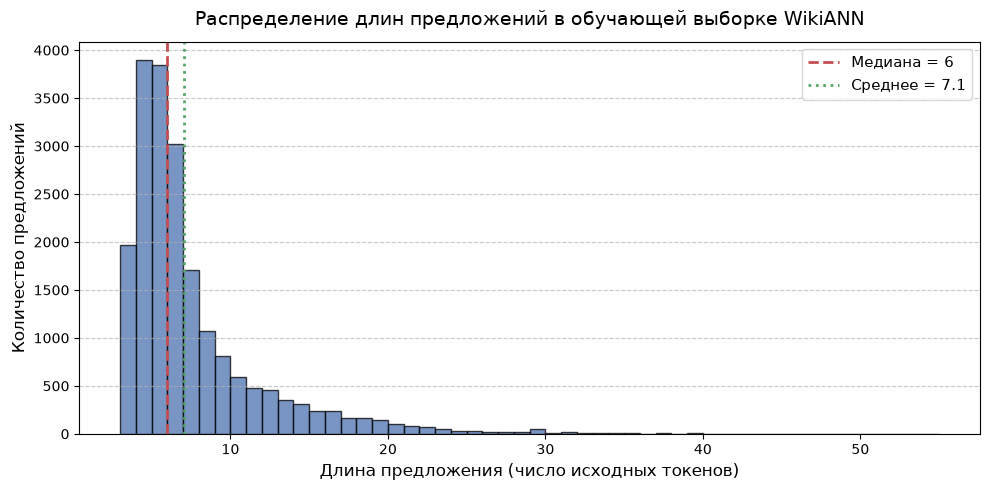

In [8]:
# Рассчитываем длины предложений и строим гистограмму
sentence_lengths = [len(example["tokens"]) for example in raw_datasets["train"]]

# Выводим минимум, максимум и медиану
min_len = int(np.min(sentence_lengths))
max_len = int(np.max(sentence_lengths))
median_len = float(np.median(sentence_lengths))
mean_len = float(np.mean(sentence_lengths))

print(f"Статистика длин предложений (по числу исходных токенов):")
print(f"  Минимум: {min_len}")
print(f"  Максимум: {max_len}")
print(f"  Медиана:  {median_len:.1f}")
print(f"  Среднее:  {mean_len:.2f}")

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(
    sentence_lengths,
    bins=range(min_len, max_len + 2),
    color="#4C72B0",
    edgecolor="black",
    alpha=0.75,
)
ax.axvline(median_len, color="#C44E52", linestyle="--", linewidth=2, label=f"Медиана = {median_len:.0f}")
ax.axvline(mean_len, color="#55A868", linestyle=":", linewidth=2, label=f"Среднее = {mean_len:.1f}")

ax.set_title("Распределение длин предложений в обучающей выборке WikiANN", fontsize=14, pad=12)
ax.set_xlabel("Длина предложения (число исходных токенов)", fontsize=12)
ax.set_ylabel("Количество предложений", fontsize=12)
ax.legend(fontsize=11)
ax.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()


### Выводы

1. **Размеры выборок и состав меток:**
   - Датасет WikiANN (русскоязычная конфигурация `ru`) разделен на обучающую (20 000 примеров), валидационную (10 000 примеров) и тестовую (10 000 примеров) выборки.
   - Разметка выполнена по схеме IOB2 со следующими 7 тегами: `O`, `B-PER`, `I-PER`, `B-ORG`, `I-ORG`, `B-LOC`, `I-LOC`. Соответственно, в датасете представлены 3 целевых типа именованных сущностей: `PER` (персоны), `ORG` (организации) и `LOC` (локации).
   
2. **Распределение типов сущностей (по меткам `B-*`):**
   - Всего в обучающей выборке (20 000 предложений) содержится **24 629** сущностей.
   - `LOC` (локации): **9 498** сущностей (**38.56%**);
   - `ORG` (организации): **7 944** сущностей (**32.25%**);
   - `PER` (персоны): **7 187** сущностей (**29.18%**).
   - *Дисбаланс классов является умеренным* (разница между самым частым классом `LOC` и наименее частым `PER` составляет около 9.38 процентных пунктов или отношение 1.32 : 1). Все три типа сущностей представлены в выборке в достаточных объемах для успешного обучения и устойчивой оценки качества.

3. **Длины предложений (по числу исходных токенов):**
   - Минимум: **3** токена;
   - Максимум: **54** токена;
   - Медиана: **6.0** токенов;
   - Среднее: **7.08** токенов.
   - Распределение скошено вправо: подавляющее большинство предложений являются короткими фрагментами энциклопедических статей, заголовками и краткими биографическими справками (типичная длина — от 4 до 9 токенов).

4. **Особенности автоматической разметки WikiANN:**
   - Датасет получен методом автоматического проецирования ссылок Википедии и связей с Wikidata, поэтому в разметке присутствует характерный шум.
   - В частности, знаки пунктуации (запятые, кавычки) могут быть включены внутрь границ сущности (например, запятая в имени `Илизаров , Гавриил Абрамович` помечена тегом `I-PER`, а кавычки вокруг названий организаций или локаций могут примыкать к сущности).
   - Встречаются изолированные заголовки и неполные синтаксические конструкции. Эти артефакты следует учитывать при анализе ошибок и интерпретации метрик модели.


## Шаг 3. Токенизация и выравнивание меток

BERT может разбить одно исходное слово на несколько токенов-подслов. В этом проекте
исходная NER-метка назначается только первому токену. Продолжения слова,
специальные токены и паддинг получают `-100` и исключаются из расчёта функции потерь.


In [ ]:
model_checkpoint = "bert-base-multilingual-cased"
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)

In [10]:
def tokenize_and_align_labels(examples):
    """Токенизирует слова и выравнивает NER-метки с подсловами."""
    tokenized_inputs = tokenizer(
        examples["tokens"],
        truncation=True,
        is_split_into_words=True,
    )

    labels = []
    for i, label in enumerate(examples["ner_tags"]):
        word_ids = tokenized_inputs.word_ids(batch_index=i)
        previous_word_idx = None
        label_ids = []

        for word_idx in word_ids:
            if word_idx is None:
                label_ids.append(-100)
            elif word_idx != previous_word_idx:
                label_ids.append(label[word_idx])
            else:
                label_ids.append(-100)
            previous_word_idx = word_idx

        labels.append(label_ids)

    tokenized_inputs["labels"] = labels
    return tokenized_inputs


### Анализ работы `word_ids()`

Для двух примеров из обучающей выборки (выбраны с фиксированным `SEED`) для каждой позиции выводится последовательность

```text
токен → word_id → метка после выравнивания
```

Так проверяются специальные токены, первый токен слова и его продолжения.

In [11]:
examples_to_trace = raw_datasets["train"].shuffle(seed=SEED).select(range(2))

for i in range(len(examples_to_trace["tokens"])):
    tokens = examples_to_trace["tokens"][i]
    tags = examples_to_trace["ner_tags"][i]
    tokenized = tokenizer(tokens, is_split_into_words=True)
    word_ids = tokenized.word_ids()
    subtokens = tokenizer.convert_ids_to_tokens(tokenized["input_ids"])

    # Выравниваем метки по тем же правилам, что и в функции выше
    aligned_labels = []
    previous_word_idx = None
    for word_idx in word_ids:
        if word_idx is None:
            aligned_labels.append(-100)
        elif word_idx != previous_word_idx:
            aligned_labels.append(tags[word_idx])
        else:
            aligned_labels.append(-100)
        previous_word_idx = word_idx

    # Выводим токен, word_id и читаемую метку для каждой позиции
    print(f"Пример {i + 1}: {' '.join(tokens)}")
    for subtoken, word_id, label_id in zip(subtokens, word_ids, aligned_labels):
        label_str = label_list[label_id] if label_id != -100 else "-100"
        print(f"  {subtoken:<16} → word_id: {str(word_id):<5} → {label_str}")
    print()


Пример 1: ' '' Польша '' ' —
  [CLS]            → word_id: None  → -100
  '                → word_id: 0     → O
  '                → word_id: 1     → O
  '                → word_id: 1     → -100
  Польша           → word_id: 2     → B-LOC
  '                → word_id: 3     → O
  '                → word_id: 3     → -100
  '                → word_id: 4     → O
  [UNK]            → word_id: 5     → O
  [SEP]            → word_id: None  → -100

Пример 2: Картина была привезена из Флоренции в Мюнхен после почти двадцатилетних переговоров и многих усилий вызволить её у прежних владельцев .
  [CLS]            → word_id: None  → -100
  К                → word_id: 0     → O
  ##арт            → word_id: 0     → -100
  ##ина            → word_id: 0     → -100
  была             → word_id: 1     → O
  при              → word_id: 2     → O
  ##ве             → word_id: 2     → -100
  ##зен            → word_id: 2     → -100
  ##а              → word_id: 2     → -100
  из               → word_id: 

### Почему используется `-100`

Метка **`-100`** - это значение `ignore_index` в PyTorch, которое полностью исключает указанные токены из расчёта функции потерь и обновления градиентов. Она назначается служебным токенам, чтобы модель не тратила ресурсы на классификацию технической структуры. Также `-100` присваивается всем частям разбитого слова, кроме первого подтокена, благодаря чему каждое исходное слово вносит одинаковый вклад в ошибку независимо от своей длины.

### Применение функции ко всему датасету

`tokenize_and_align_labels` применяется к обучающей, валидационной и тестовой выборкам через `.map()` с `batched=True`; исходные столбцы удаляются через `remove_columns`.

In [ ]:
# Применяем tokenize_and_align_labels ко всем выборкам
tokenized_datasets = raw_datasets.map(
    tokenize_and_align_labels,
    batched=True,
    remove_columns=raw_datasets["train"].column_names,
)

print("Токенизация и выравнивание успешно выполнены для всех выборок:")
for split in ["train", "validation", "test"]:
    print(f"  {split:12s}: {len(tokenized_datasets[split]):5d} примеров, колонки: {tokenized_datasets[split].column_names}")

Токенизация и выравнивание успешно выполнены для всех выборок:
  train       : 20000 примеров, колонки: ['input_ids', 'token_type_ids', 'attention_mask', 'labels']
  validation  : 10000 примеров, колонки: ['input_ids', 'token_type_ids', 'attention_mask', 'labels']
  test        : 10000 примеров, колонки: ['input_ids', 'token_type_ids', 'attention_mask', 'labels']


### Проверка выравнивания

Для каждого примера во всех выборках проверяется равенство длин `input_ids`, `attention_mask`, `labels`. На первых 100 примерах каждой выборки дополнительно проверяется, что `-100` стоит на специальных токенах и продолжениях слов.

In [ ]:
# Проверяем длины для каждого примера во всех трёх выборках
for split in ["train", "validation", "test"]:
    for i, example in enumerate(tokenized_datasets[split]):
        assert (
            len(example["input_ids"]) == len(example["attention_mask"]) == len(example["labels"])
        ), f"Несовпадение длин полей в {split}, пример {i}"
    print(f" Проверка длин: len(input_ids) == len(attention_mask) == len(labels) пройдена для всех {len(tokenized_datasets[split])} примеров в {split}")

# Проверяем позиции -100 на первых 100 примерах каждой выборки
for split in ["train", "validation", "test"]:
    for i in range(100):
        raw_tokens = raw_datasets[split][i]["tokens"]
        raw_tags = raw_datasets[split][i]["ner_tags"]
        tokenized = tokenizer(raw_tokens, is_split_into_words=True)
        word_ids = tokenized.word_ids()
        labels = tokenized_datasets[split][i]["labels"]

        for pos, (w_id, label) in enumerate(zip(word_ids, labels)):
            if w_id is None:
                assert label == -100, f"Специальный токен на позиции {pos} имеет метку {label} != -100 в {split}[{i}]"
            elif pos > 0 and word_ids[pos - 1] == w_id:
                assert label == -100, f"Продолжение слова на позиции {pos} имеет метку {label} != -100 в {split}[{i}]"
            else:
                assert label == raw_tags[w_id], f"Первый подтокен на позиции {pos} получил метку {label} != {raw_tags[w_id]} в {split}[{i}]"
    print(f" Проверка позиций -100 и меток первых подтокенов пройдена на первых 100 примерах в {split}")


✓ Проверка длин: len(input_ids) == len(attention_mask) == len(labels) пройдена для всех 20000 примеров в train


✓ Проверка длин: len(input_ids) == len(attention_mask) == len(labels) пройдена для всех 10000 примеров в validation
✓ Проверка длин: len(input_ids) == len(attention_mask) == len(labels) пройдена для всех 10000 примеров в test
✓ Проверка позиций -100 и меток первых подтокенов пройдена на первых 100 примерах в train
✓ Проверка позиций -100 и меток первых подтокенов пройдена на первых 100 примерах в validation
✓ Проверка позиций -100 и меток первых подтокенов пройдена на первых 100 примерах в test


### Проверка динамического паддинга

Коллатор и демонстрационный батч из четырёх примеров: формы `input_ids`, `attention_mask`, `labels` и метки на позициях padding.

In [ ]:
data_collator = DataCollatorForTokenClassification(tokenizer=tokenizer)

# Формируем батч из четырёх обучающих примеров
batch_examples = [tokenized_datasets["train"][i] for i in range(4)]
batch = data_collator(batch_examples)

# Проверяем равенство форм
print("Формы тензоров в сформированном батче:")
print(f"  input_ids:      {list(batch['input_ids'].shape)}")
print(f"  attention_mask: {list(batch['attention_mask'].shape)}")
print(f"  labels:         {list(batch['labels'].shape)}")

assert (
    batch["input_ids"].shape == batch["attention_mask"].shape == batch["labels"].shape
), "Формы тензоров input_ids, attention_mask и labels в батче не совпадают!"
print(" Формы всех трёх тензоров в батче совпадают.")

# Проверяем attention_mask == 0 и labels == -100 на padding
padding_positions = (batch["attention_mask"] == 0)
if padding_positions.any():
    assert (batch["labels"][padding_positions] == -100).all(), "На позициях паддинга labels != -100!"
    print(" На всех позициях dynamic padding: attention_mask == 0 и labels == -100.")
else:
    print("В данном батче длина всех 4 примеров оказалась равной, паддинг не потребовался.")

# Проверяем целочисленный dtype поля labels в батче
print(f"  dtype поля labels: {batch['labels'].dtype}")
assert batch["labels"].dtype == torch.int64, f"Неверный dtype labels: {batch['labels'].dtype}"
print(" Поле labels имеет корректный целочисленный тип (torch.int64).")


Формы тензоров в сформированном батче:
  input_ids:      [4, 43]
  attention_mask: [4, 43]
  labels:         [4, 43]
✓ Формы всех трёх тензоров в батче строго совпадают.
✓ На всех позициях dynamic padding: attention_mask == 0 и labels == -100.
  dtype поля labels: torch.int64
✓ Поле labels имеет корректный целочисленный тип (torch.int64).


### Вывод

1. **Готовность данных к обучению:**
   - Валидация подтвердила, что для всех примеров во всех трёх выборках выполняется равенство длин `len(input_ids) == len(attention_mask) == len(labels)`.
   - На выборках проверено соблюдение логики расстановки `-100`: специальные токены (`[CLS]`, `[SEP]`) и все подтокены-продолжения получают значение `-100`, а первый подтокен каждого слова сохраняет исходную метку сущности.

2. **Назначение `word_ids()` и `-100`:**
   - Метод `word_ids()` связывает каждый сгенерированный подтокен с индексом соответствующего исходного слова в списке `tokens` (`None` для служебных токенов, `0, 1, 2...` для слов предложения). Это позволяет однозначно определить границы исходных слов после разбиения токенизатором BERT.
   - Метка `-100` выступает в роли `ignore_index` для функции потерь `CrossEntropyLoss`. Она исключает служебные токены, подтокены-продолжения и позиции динамического паддинга из расчета градиентов и ошибок, предотвращая смещение весов в пользу многосоставных слов и избавляя модель от ложного штрафа.

3. **Корректность динамического паддинга:**
   - Проверка с использованием `DataCollatorForTokenClassification` показала, что батчи динамически дополняются до максимальной длины в батче, на всех позициях паддинга выставляется `attention_mask == 0` и `labels == -100`, а тензор `labels` имеет корректный целочисленный тип `torch.int64`.


## Итог подготовки данных

Данные подготовлены к обучению: метки выровнены с подтокенами, длины полей совпадают, паддинг формируется корректно. Обучение моделей, эксперименты с объёмом обучающей выборки и анализ ошибок — во второй части проекта (`Извлечение именованных сущностей. Часть 2 — эксперименты.ipynb`).

## Ресурсы

- [WikiANN](https://huggingface.co/datasets/unimelb-nlp/wikiann)
- [Hugging Face Datasets](https://huggingface.co/docs/datasets/)
- [Hugging Face: Token Classification](https://huggingface.co/docs/transformers/tasks/token_classification)
- [bert-base-multilingual-cased](https://huggingface.co/bert-base-multilingual-cased)